# Taller de Machine Learning Supervisado - Reconocimiento de Vocales (OCR)

**Asignatura:** Inteligencia Artificial - Universidad del Magdalena

**Curso:** IA-2026-II  |  **Tema:** Reconocimiento óptico de caracteres (OCR)

**Integrantes y Asignación de Métodos:**
- **Carlos Pinto:** Regresión Multivariada (Logística Multinomial)
- **Jorge García:** Random Forest
- **Santiago Gonzales:** Árboles de Decisión
- **León Cantillo:** Redes Neuronales (MLP y DNN)

## Contenido del equipo
- Clases asignadas: vocales **A, E, I, O, U**.
- La vocal **O** se representa con la carpeta **`0`** (no existe un directorio propio para la letra O en el dataset, por similitud visual con el dígito cero).

## Alcance de este cuaderno
Este cuaderno contiene la inspección y exploración visual del dataset de vocales, el preprocesamiento, escalado y preparación estandarizada de matrices de características $X$ y vectores de etiquetas $y$, la partición estratificada por grupos (sin fuga de información) y la reducción de dimensionalidad con PCA, sirviendo como base común para los modelos supervisados del equipo.


## 1. Descripción del problema

El reconocimiento óptico de caracteres (OCR) permite identificar caracteres presentes en imágenes y convertirlos en texto digital editable. En este trabajo el conjunto de datos contiene imágenes manuscritas de caracteres, y el equipo se enfoca en las cinco vocales: **A, E, I, O, U**, donde la **O** se aproxima mediante el directorio del dígito `0`.

Esta decisión debe tenerse en cuenta al interpretar los resultados, ya que la letra O y el número 0 son caracteres distintos aunque presenten formas similares.


## 2. Configuración y carga del dataset

Se configura la ruta del dataset y se cargan solo las carpetas de clase correspondientes a vocales. El dataset completo (**CNN letter Dataset**) no se incluye en este repositorio por su peso.


In [1]:
import os
import re
import zipfile
import hashlib
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)
np.random.seed(42)
plt.rcParams["figure.dpi"] = 100

# ---------------------------------------------------------------
# CONFIGURACIÓN
# ---------------------------------------------------------------
# Ruta del dataset (ajustar si es necesario). El dataset no se sube al repo por su peso.
RUTA_DATASET = r"CNN letter Dataset"
RUTA_ZIP = "archive (1).zip"
EXT = {".png", ".jpg", ".jpeg", ".bmp", ".gif", ".tif", ".tiff"}

# Vocales que analiza este grupo. Se excluyen números 1-9 y otras letras.
VOCALES = ["A", "E", "I", "O", "U"]

def _tiene_clases(carpeta: Path) -> bool:
    subs = [d for d in carpeta.iterdir() if d.is_dir() and not d.name.startswith(("__", "."))]
    con_imgs = [d for d in subs if any(f.suffix.lower() in EXT for f in d.iterdir() if f.is_file())]
    return len(con_imgs) >= 2

def encontrar_raiz() -> Path:
    p = Path(RUTA_DATASET)
    if p.is_dir() and _tiene_clases(p):
        return p
    candidatos_zip = [Path(RUTA_ZIP), Path("/mnt/user-data/uploads") / RUTA_ZIP]
    for z in candidatos_zip:
        if z.is_file():
            destino = Path("dataset_extraido")
            if not destino.exists():
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(destino)
            break
    for base in [Path("dataset_extraido"), Path(".")]:
        if base.is_dir():
            for d in [base] + [x for x in base.rglob("*") if x.is_dir()]:
                if "__MACOSX" in d.parts:
                    continue
                if _tiene_clases(d):
                    return d
    raise FileNotFoundError(
        "No se encontró el dataset. Ajuste RUTA_DATASET o RUTA_ZIP en esta celda."
    )

RAIZ = encontrar_raiz()
print("Dataset encontrado en:", RAIZ.resolve())


Dataset encontrado en: /run/media/lion/C6DA3E68DA3E5541/Lion/College/IA/trabajo 2/vowel-recognizer-ml/CNN letter Dataset


## 3. Organización de archivos y carpetas

Se muestra el árbol de carpetas restringido a las clases de vocales. Cada subcarpeta es una clase.


In [2]:
for carpeta, subs, archivos in os.walk(RAIZ):
    if "__MACOSX" in carpeta:
        continue
    nombre = Path(carpeta).name
    # Solo mostrar carpetas de clase vocales o la raíz
    if carpeta == str(RAIZ) or nombre in VOCALES or nombre == "0":
        nivel = len(Path(carpeta).relative_to(RAIZ).parts)
        print("  " * nivel + f"{nombre}/  ({len(archivos)} archivos)")

print("\nEjemplos de nombres de archivo por vocal:")
for d in sorted(x for x in RAIZ.iterdir() if x.is_dir() and (x.name in VOCALES or x.name == "0")):
    print(f"  {d.name}: {[f.name for f in sorted(d.iterdir())[:3]]}")


CNN letter Dataset/  (0 archivos)
  0/  (1030 archivos)
  A/  (1010 archivos)
  E/  (1010 archivos)
  I/  (1010 archivos)
  U/  (1010 archivos)

Ejemplos de nombres de archivo por vocal:
  0: ['aug17401_0.jpg', 'aug17402_1.jpg', 'aug17403_2.jpg']
  A: ['aug100_19.jpg', 'aug100_9.jpg', 'aug101_0.jpg']
  E: ['aug1061_0.jpg', 'aug1062_1.jpg', 'aug1063_2.jpg']
  I: ['aug2581_0.jpg', 'aug2582_1.jpg', 'aug2583_2.jpg']
  U: ['aug13601_0.jpg', 'aug13602_1.jpg', 'aug13603_2.jpg']


## 4. Cantidad de imágenes por clase

Se construye una tabla con la ruta, clase y formato de cada imagen. La carpeta `0` se mapea a la vocal `O`. Se excluyen del análisis las carpetas de números del 1 al 9 y demás letras que no sean vocales.


Total de imágenes (vocales): 5070
Clases (vocales): ['A', 'E', 'I', 'O', 'U']

Conteo por vocal:
clase
A    1010
E    1010
I    1010
O    1030
U    1010

Total: 5070
Razón entre la clase más y menos frecuente: 1.02


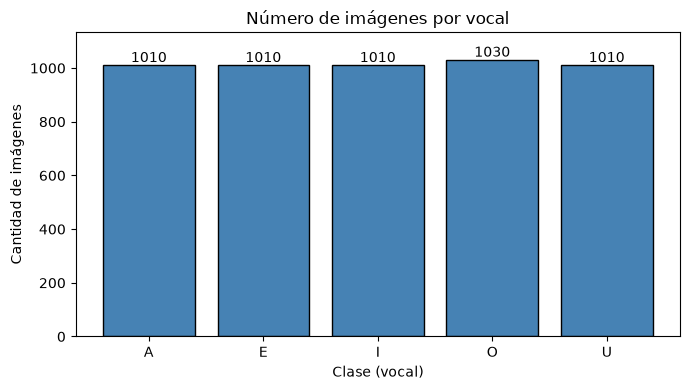

,ruta,clase,formato
0,CNN letter Dataset/0/aug17706_5.jpg,O,.jpg
1,CNN letter Dataset/0/aug18012_1.jpg,O,.jpg
2,CNN letter Dataset/0/aug18409_8.jpg,O,.jpg
3,CNN letter Dataset/0/aug18410_9.jpg,O,.jpg
4,CNN letter Dataset/0/aug8041_0.jpg,O,.jpg


In [3]:
registros = []
for p in RAIZ.rglob("*"):
    if p.is_file() and p.suffix.lower() in EXT and "__MACOSX" not in p.parts:
        clase = p.parent.name
        # Mapear carpeta '0' a vocal 'O'
        if clase == "0":
            clase = "O"
        # Filtrar solo vocales (excluir números 1-9 y otras letras)
        if clase in VOCALES:
            registros.append({"ruta": p, "clase": clase, "formato": p.suffix.lower()})

df = pd.DataFrame(registros)
CLASES = sorted(df["clase"].unique())

print("Total de imágenes (vocales):", len(df))
print("Clases (vocales):", CLASES)

conteo = df["clase"].value_counts().reindex(VOCALES).fillna(0).astype(int)
print("\nConteo por vocal:")
print(conteo.to_string())
print("\nTotal:", int(conteo.sum()))
print("Razón entre la clase más y menos frecuente:", round(conteo.max() / conteo.min(), 3))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(conteo.index, conteo.values, color="steelblue", edgecolor="black")
ax.set_title("Número de imágenes por vocal")
ax.set_xlabel("Clase (vocal)")
ax.set_ylabel("Cantidad de imágenes")
ax.set_ylim(0, conteo.max() * 1.1)
for b, v in zip(barras, conteo.values):
    ax.text(b.get_x() + b.get_width() / 2, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()
df.head()


## 5. Muestras aleatorias por clase

Se seleccionan imágenes aleatorias de cada vocal y se muestran en una cuadrícula para observar variaciones de escritura, fondo, iluminación, grosor de trazo, rotación o ruido.


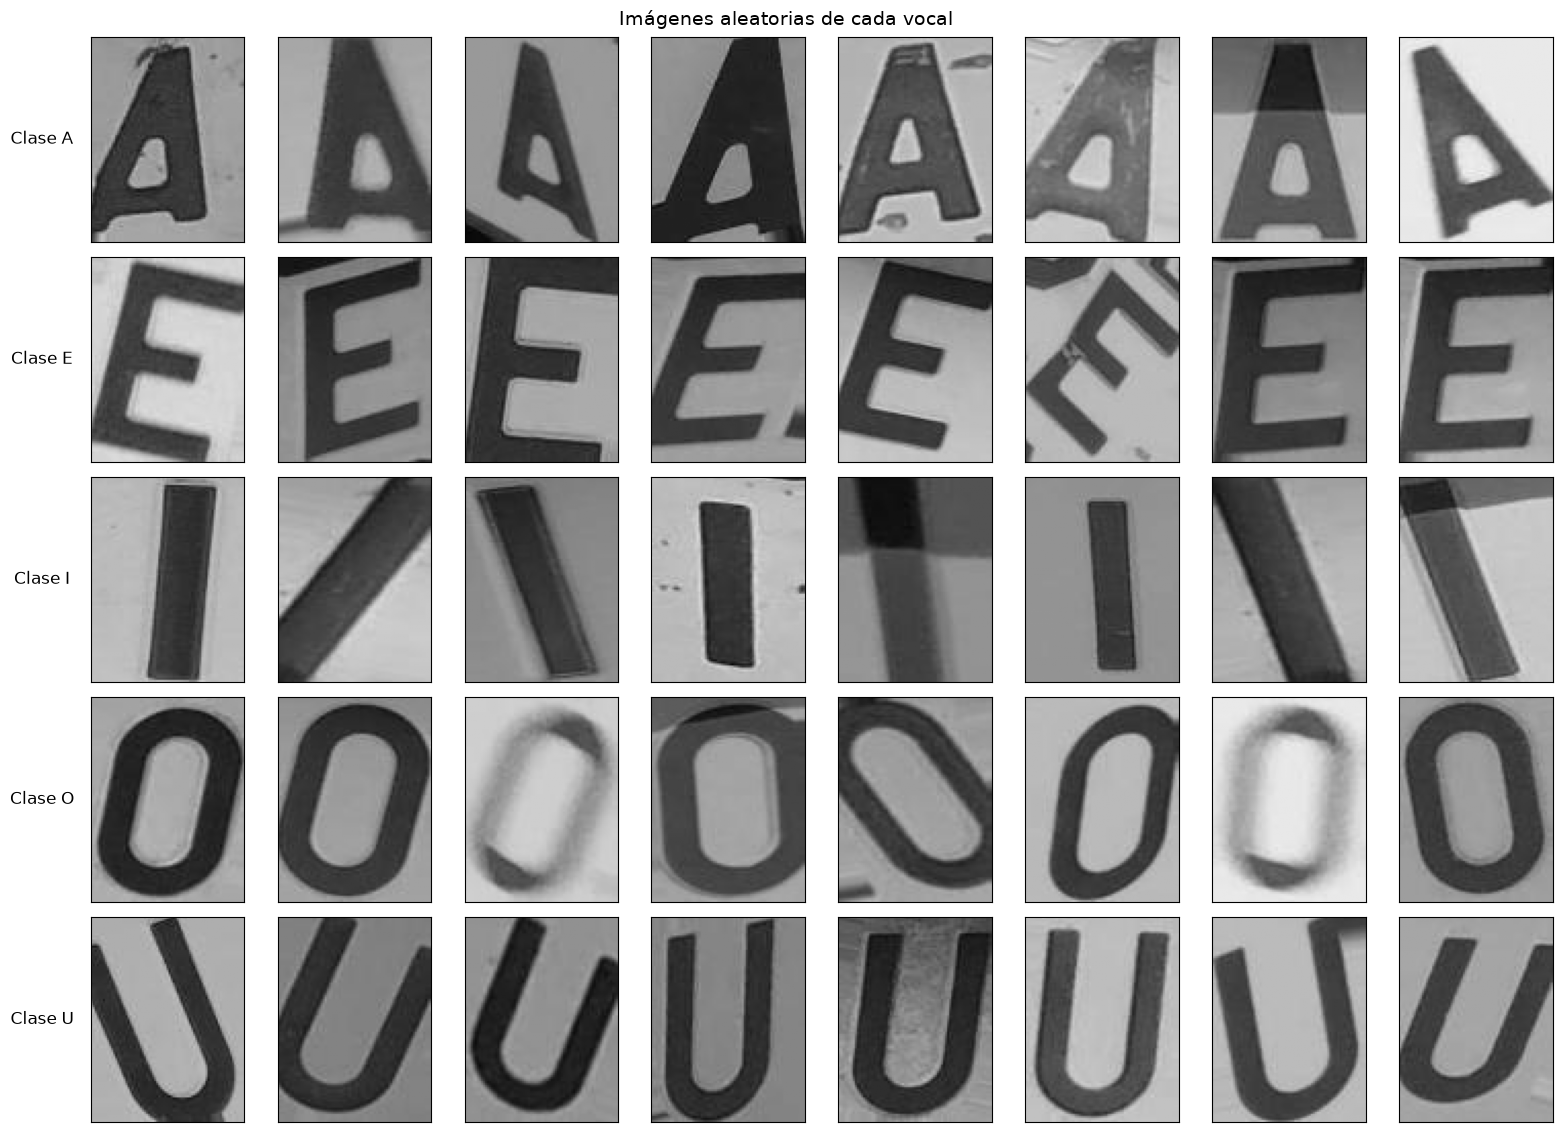

In [4]:
N_POR_CLASE = 8
rng = np.random.RandomState(7)

fig, axes = plt.subplots(len(CLASES), N_POR_CLASE, figsize=(2 * N_POR_CLASE, 2.3 * len(CLASES)))
for i, c in enumerate(CLASES):
    sub = df[df["clase"] == c]
    idx = rng.choice(len(sub), size=min(N_POR_CLASE, len(sub)), replace=False)
    for j, k in enumerate(idx):
        with Image.open(sub.iloc[k]["ruta"]) as im:
            a = np.array(im)
        ax = axes[i, j]
        ax.imshow(a, cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(f"Clase {c}", fontsize=12, rotation=0, labelpad=35, va="center")
fig.suptitle("Imágenes aleatorias de cada vocal", fontsize=14)
plt.tight_layout()
plt.show()


## 6. Dimensiones, canales y formato

Se verifican todas las imágenes del subconjunto de vocales: tamaño, modo de color, número de canales, tipo de dato y rango de intensidades. Se determina si todas tienen el mismo tamaño.


In [5]:
filas = []
for ruta, clase in zip(df["ruta"], df["clase"]):
    try:
        with Image.open(ruta) as im:
            a = np.array(im)
            filas.append({
                "clase": clase,
                "ancho": im.size[0],
                "alto": im.size[1],
                "modo": im.mode,
                "canales": 1 if a.ndim == 2 else a.shape[2],
                "dtype": str(a.dtype),
                "min": int(a.min()),
                "max": int(a.max()),
                "media": float(a.mean()),
                "desv": float(a.std()),
            })
    except Exception as e:
        filas.append({"clase": clase, "ancho": np.nan, "alto": np.nan, "modo": "ERROR",
                      "canales": np.nan, "dtype": "", "min": np.nan, "max": np.nan,
                      "media": np.nan, "desv": np.nan})

info = pd.DataFrame(filas)
info["ruta"] = df["ruta"].values

print("Tamaños (ancho, alto) y frecuencia:")
print(info.groupby(["ancho", "alto"]).size().to_string())
print("\nModos de color:\n", info["modo"].value_counts().to_string())
print("\nNúmero de canales:\n", info["canales"].value_counts().to_string())
print("\nTipo de dato:\n", info["dtype"].value_counts().to_string())
print("\nFormato de archivo:\n", df["formato"].value_counts().to_string())

mismo_tamano = info[["ancho", "alto"]].drop_duplicates().shape[0] == 1
print("\n¿Todas las imágenes tienen el mismo tamaño?", mismo_tamano)


Tamaños (ancho, alto) y frecuencia:
ancho  alto
75     100     5070

Modos de color:
 modo
L    5070

Número de canales:
 canales
1    5070

Tipo de dato:
 dtype
uint8    5070

Formato de archivo:
 formato
.jpg    5070

¿Todas las imágenes tienen el mismo tamaño? True


## 7. Calidad de los datos

Se revisa: imágenes corruptas o ilegibles, duplicados exactos por contenido, imágenes idénticas en clases distintas, brillo/contraste atípicos y el patrón de los nombres de archivo.


Imágenes corruptas: 0
Archivos duplicados exactos: 0
Contenidos repetidos en clases distintas: 0

Valores faltantes en la tabla de metadatos:
ruta       0
clase      0
formato    0

Imágenes con desviación estándar < 10 (poco contraste): 0


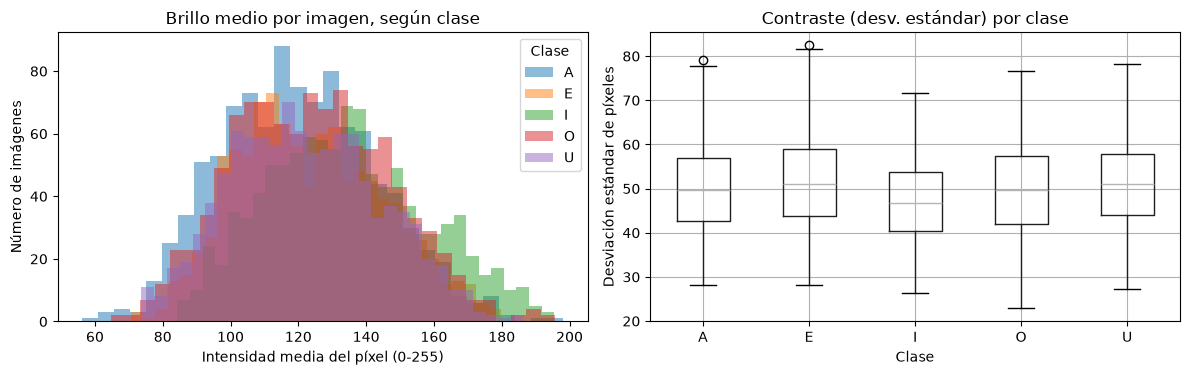


Archivos que siguen el patrón 'aug<id>_<sufijo>': 5070 de 5070


In [6]:
# 1) Imágenes corruptas o ilegibles
corruptas = []
for ruta in df["ruta"]:
    try:
        with Image.open(ruta) as im:
            im.verify()
    except Exception:
        corruptas.append(ruta)
print("Imágenes corruptas:", len(corruptas))

# 2) Duplicados exactos por contenido (hash MD5)
def md5(ruta):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        h.update(f.read())
    return h.hexdigest()

df["hash"] = [md5(r) for r in df["ruta"]]
print("Archivos duplicados exactos:", int(df["hash"].duplicated().sum()))
print("Contenidos repetidos en clases distintas:", int((df.groupby("hash")["clase"].nunique() > 1).sum()))

# 3) Valores faltantes en la tabla de metadatos
print("\nValores faltantes en la tabla de metadatos:")
print(df[["ruta", "clase", "formato"]].isna().sum().to_string())

# 4) Imágenes casi uniformes (poco contraste) o muy oscuras/claras
UMBRAL_DESV = 10
poco_contraste = info[info["desv"] < UMBRAL_DESV]
print(f"\nImágenes con desviación estándar < {UMBRAL_DESV} (poco contraste): {len(poco_contraste)}")
if len(poco_contraste):
    print(poco_contraste["clase"].value_counts().to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for c in CLASES:
    axes[0].hist(info.loc[info["clase"] == c, "media"], bins=30, alpha=0.5, label=c)
axes[0].set_title("Brillo medio por imagen, según clase")
axes[0].set_xlabel("Intensidad media del píxel (0-255)")
axes[0].set_ylabel("Número de imágenes")
axes[0].legend(title="Clase")

info.boxplot(column="desv", by="clase", ax=axes[1])
axes[1].set_title("Contraste (desv. estándar) por clase")
axes[1].set_xlabel("Clase")
axes[1].set_ylabel("Desviación estándar de píxeles")
plt.suptitle("")
plt.tight_layout()
plt.show()

# 5) Patrón de los nombres de archivo
patron = re.compile(r"^aug(\d+)_(\d+)$")
nombres = df["ruta"].apply(lambda p: Path(p).stem)
coincide = nombres.apply(lambda s: bool(patron.match(s)))
print(f"\nArchivos que siguen el patrón 'aug<id>_<sufijo>': {coincide.sum()} de {len(df)}")


## 8. Exploración gráfica adicional

### Imagen promedio por clase y distribución de intensidades

La imagen promedio permite ver qué forma "típica" tiene cada vocal; el histograma de intensidades ayuda a decidir si es necesario normalizar los píxeles.


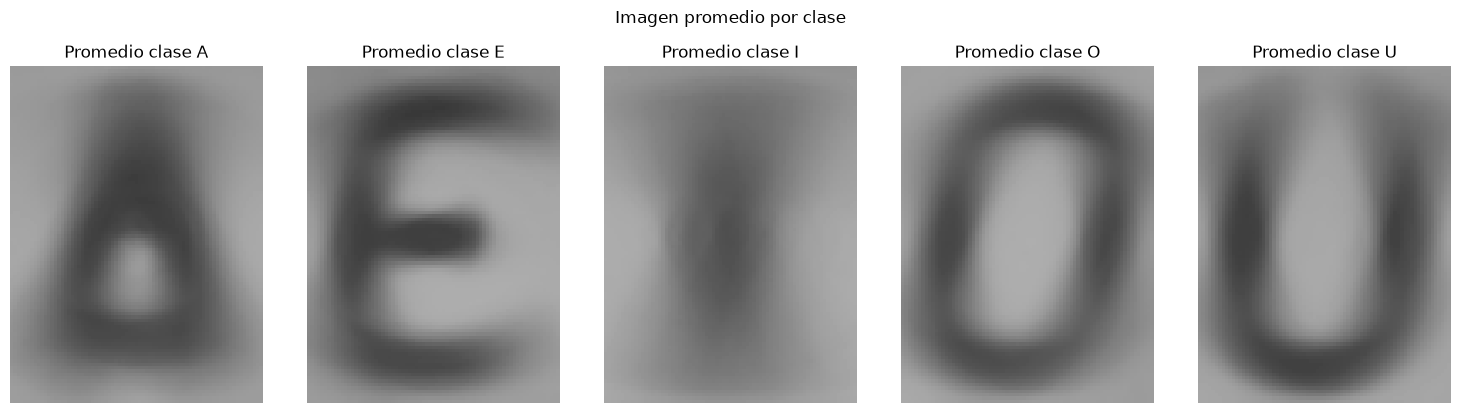

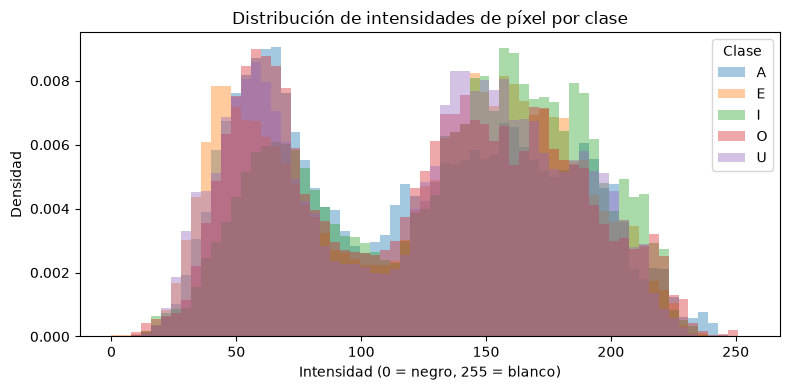

In [7]:
# Imagen promedio por clase
if not mismo_tamano:
    print("Las imágenes no tienen todas el mismo tamaño; se omite la imagen promedio.")
else:
    H, W = int(info["alto"].iloc[0]), int(info["ancho"].iloc[0])
    promedios = {}
    for c in CLASES:
        suma = np.zeros((H, W), dtype=np.float64)
        rutas = df.loc[df["clase"] == c, "ruta"]
        for r in rutas:
            with Image.open(r) as im:
                suma += np.array(im.convert("L"), dtype=np.float64)
        promedios[c] = suma / len(rutas)

    fig, axes = plt.subplots(1, len(CLASES), figsize=(3 * len(CLASES), 4))
    for ax, c in zip(axes, CLASES):
        ax.imshow(promedios[c], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"Promedio clase {c}")
        ax.axis("off")
    plt.suptitle("Imagen promedio por clase", y=1.02)
    plt.tight_layout()
    plt.show()

# Histograma de intensidades de píxel (muestra de 300 imágenes por clase)
fig, ax = plt.subplots(figsize=(8, 4))
for c in CLASES:
    sub = df[df["clase"] == c].sample(min(300, (df["clase"] == c).sum()), random_state=42)
    pix = np.concatenate([np.array(Image.open(r).convert("L")).ravel() for r in sub["ruta"]])
    ax.hist(pix, bins=64, range=(0, 255), alpha=0.4, density=True, label=c)
ax.set_title("Distribución de intensidades de píxel por clase")
ax.set_xlabel("Intensidad (0 = negro, 255 = blanco)")
ax.set_ylabel("Densidad")
ax.legend(title="Clase")
plt.tight_layout()
plt.show()


## 9. Resumen cuantitativo de la inspección


In [8]:
resumen_final = pd.DataFrame({
    "Aspecto": [
        "Total de imágenes",
        "Número de clases",
        "Clases",
        "Imagen más/menos frecuente (razón)",
        "Formatos de archivo",
        "Tamaños distintos (ancho x alto)",
        "Modos de color",
        "Canales",
        "Imágenes corruptas",
        "Duplicados exactos",
        "Contenido repetido entre clases",
        "Imágenes con poco contraste",
    ],
    "Valor": [
        len(df),
        len(CLASES),
        ", ".join(CLASES),
        round(conteo.max() / conteo.min(), 3),
        ", ".join(df["formato"].unique()),
        "; ".join(f"{int(a)}x{int(b)}" for a, b in info[["ancho", "alto"]].drop_duplicates().values),
        ", ".join(info["modo"].unique()),
        ", ".join(str(int(x)) for x in info["canales"].dropna().unique()),
        len(corruptas),
        int(df["hash"].duplicated().sum()),
        int((df.groupby("hash")["clase"].nunique() > 1).sum()),
        len(poco_contraste),
    ],
})
resumen_final


,Aspecto,Valor
0,Total de imágenes,5070
1,Número de clases,5
2,Clases,"A, E, I, O, U"
3,Imagen más/menos frecuente (razón),1.02
4,Formatos de archivo,.jpg
5,Tamaños distintos (ancho x alto),75x100
6,Modos de color,L
7,Canales,1
8,Imágenes corruptas,0
9,Duplicados exactos,0


## 10. Tratamientos propuestos para etapas posteriores

Con base en los hallazgos anteriores, se justifica qué tratamiento podría ser necesario más adelante (por ejemplo, redimensionado, conversión a escala de grises, normalización de intensidades, eliminación de duplicados o aumento de datos).


## 11. Preparación de las imágenes   

### 11.1 Homogenización
Todas las imágenes deben tener el mismo tamaño para poder representarlas como vectores de igual longitud.

In [9]:
# Tamaño objetivo (ancho, alto). Se usa el tamaño original del dataset.
ANCHO, ALTO = 75, 100

imgs_homog = []
n_redimensionadas = 0

for ruta in df["ruta"]:
    with Image.open(ruta) as im:
        im = im.copy()
    if im.size != (ANCHO, ALTO):          # 1) se revisa el tamaño original
        n_redimensionadas += 1            # 2) se cuenta
        im = im.resize((ANCHO, ALTO), Image.BILINEAR)   # 3) se redimensiona
    imgs_homog.append(im)

print("Imágenes procesadas:", len(imgs_homog))
print("Imágenes que hubo que redimensionar:", n_redimensionadas)
print("Tamaños finales:", pd.Series([im.size for im in imgs_homog]).value_counts().to_dict())
print("Modos:", pd.Series([im.mode for im in imgs_homog]).value_counts().to_dict())

Imágenes procesadas: 5070
Imágenes que hubo que redimensionar: 0
Tamaños finales: {(75, 100): 5070}
Modos: {'L': 5070}


### 11.2 Conversión a escala de grises

Todas las imágenes homogenizadas se convierten al modo `'L'` (escala de grises, canal único con intensidades enteras entre 0 y 255). Se compilan en una matriz tridimensional `X_img` de dimensiones $(N, 100, 75)$ de tipo `uint8`, junto con el vector de etiquetas de clase `y`.


In [10]:
imgs_gris = [im.convert("L") for im in imgs_homog]

# Arreglo final: (n_imágenes, alto, ancho), valores 0-255
X_img = np.stack([np.array(im, dtype=np.uint8) for im in imgs_gris])
y = df["clase"].values

print("Forma de X_img:", X_img.shape, "| tipo:", X_img.dtype)
print("Rango de píxeles:", X_img.min(), "-", X_img.max())
print("Clases en y:", np.unique(y))

Forma de X_img: (5070, 100, 75) | tipo: uint8
Rango de píxeles: 0 - 255
Clases en y: ['A' 'E' 'I' 'O' 'U']


### 11.3 Comparación de imágenes antes y después de la preparación

Se seleccionan aleatoriamente muestras de las distintas vocales para inspeccionar visualmente que la homogenización y conversión a escala de grises preserven íntegramente la morfología de los trazos manuscritos.


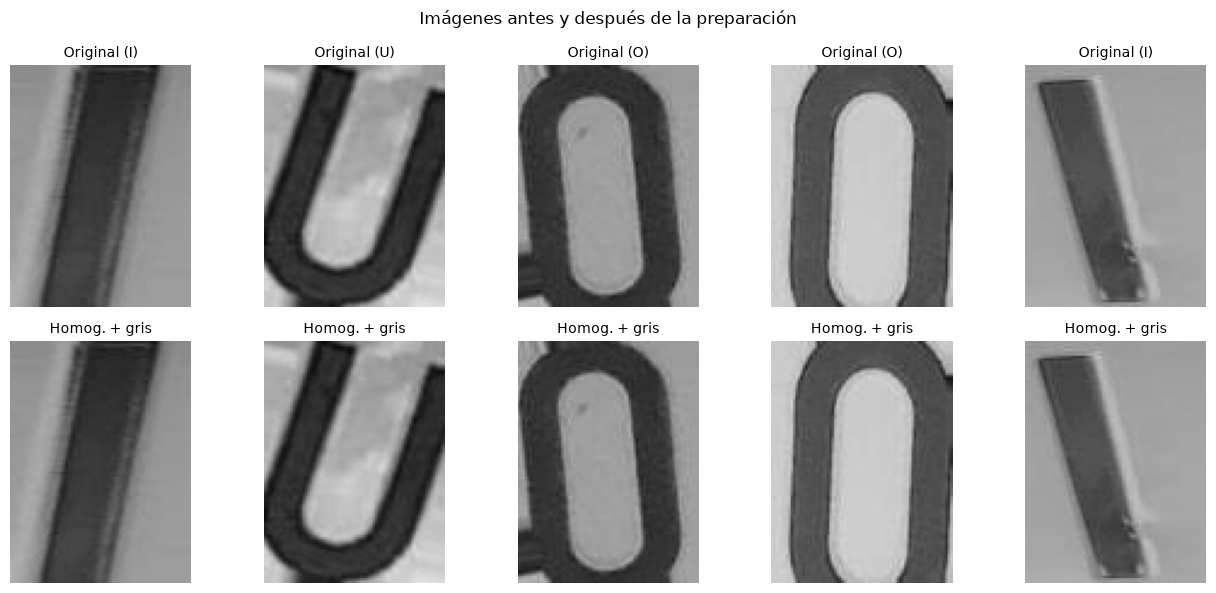

In [11]:
idx = np.random.RandomState(3).choice(len(df), 5, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for j, k in enumerate(idx):
    with Image.open(df.iloc[k]["ruta"]) as im:
        axes[0, j].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, j].set_title(f"Original ({df.iloc[k]['clase']})", fontsize=10)
    axes[1, j].imshow(X_img[k], cmap="gray", vmin=0, vmax=255)
    axes[1, j].set_title("Homog. + gris", fontsize=10)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.suptitle("Imágenes antes y después de la preparación")
plt.tight_layout()
plt.show()

### 11.4 Aplanado (Flattening): de matriz de píxeles a vector de características

Los algoritmos clásicos de Machine Learning supervisado requieren como entrada una matriz bidimensional $(N, D)$, donde cada fila representa una muestra y cada columna una característica numérica. Mediante el aplanado (*flattening*), cada imagen de $100 \times 75$ píxeles se convierte en un vector unidimensional de $7.500$ valores, preservando la correspondencia posicional de cada píxel de forma completamente reversible.


Forma antes: (5070, 100, 75)
Forma después: (5070, 7500)
¿Reversible? True

Imagen mostrada: índice 860 | archivo aug18245_4.jpg | clase O


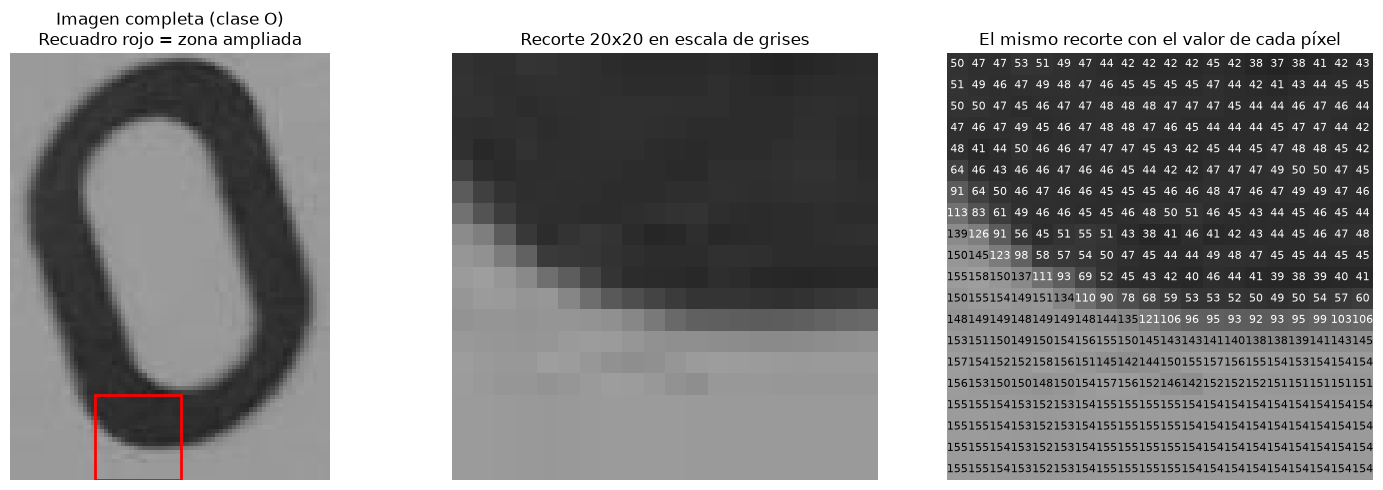

Matriz del recorte: (20, 20) -> vector aplanado: (400,)
Primeros 20 valores del vector: [50 47 47 53 51 49 47 44 42 42 42 42 45 42 38 37 38 41 42 43]
Imagen completa: (100, 75) -> vector: (7500,)


In [12]:
# ---------- Flattening: de matriz de píxeles a vector ----------
# Cada imagen (100 x 75) se convierte en un vector de 7500 valores
X_flat = X_img.reshape(len(X_img), -1)

print("Forma antes:", X_img.shape)
print("Forma después:", X_flat.shape)
print("¿Reversible?", np.array_equal(X_flat[0].reshape(ALTO, ANCHO), X_img[0]))

# ---------- Visualización del flattening en una imagen ----------
k = None   # None = imagen aleatoria en cada ejecución; o un número (0 a 5069) para fijarla
T = 20     # tamaño (T x T) del recorte que se amplía

if k is None:
    k = int(np.random.randint(len(X_img)))
print(f"\nImagen mostrada: índice {k} | archivo {df.loc[k, 'ruta'].name} | clase {df.loc[k, 'clase']}")

# Se busca la zona de T x T con más contraste (donde el trazo cruza el fondo)
f0, c0 = max(
    ((f, c) for f in range(0, ALTO - T + 1, 5) for c in range(0, ANCHO - T + 1, 5)),
    key=lambda p: X_img[k, p[0]:p[0]+T, p[1]:p[1]+T].std(),
)
recorte = X_img[k, f0:f0+T, c0:c0+T]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(X_img[k], cmap="gray", vmin=0, vmax=255)
axes[0].add_patch(plt.Rectangle((c0-0.5, f0-0.5), T, T, fill=False, edgecolor="red", linewidth=2))
axes[0].set_title(f"Imagen completa (clase {df.loc[k, 'clase']})\nRecuadro rojo = zona ampliada")
axes[0].axis("off")

axes[1].imshow(recorte, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Recorte {T}x{T} en escala de grises")
axes[1].axis("off")

axes[2].imshow(recorte, cmap="gray", vmin=0, vmax=255)
for i in range(T):
    for j in range(T):
        v = int(recorte[i, j])
        axes[2].text(j, i, str(v), ha="center", va="center", fontsize=8,
                     color="white" if v < 128 else "black")
axes[2].set_title("El mismo recorte con el valor de cada píxel")
axes[2].axis("off")
plt.tight_layout()
plt.show()

vec = recorte.reshape(-1)
print("Matriz del recorte:", recorte.shape, "-> vector aplanado:", vec.shape)
print("Primeros 20 valores del vector:", vec[:20])
print("Imagen completa:", X_img[k].shape, "-> vector:", X_flat[k].shape)

### 11.5 Normalización y escalado de variables $[0, 1]$

Siguiendo la metodología del cuaderno de referencia de la asignatura ([`PCA_MNIST_dimensionality_reduction.ipynb`](https://github.com/idanis/IA_Unimagdalena/blob/main/PCA/PCA_MNIST_dimensionality_reduction.ipynb)), los valores de intensidad de los píxeles (enteros de $0$ a $255$) se escalan al intervalo continuo $[0.0, 1.0]$ dividiendo por $255.0$.

Esta normalización es fundamental en visión computacional y aprendizaje de máquinas porque:
- Estandariza la escala para optimizadores basados en gradientes (Redes Neuronales y Regresión Logística).
- Facilita el cálculo numérico de covarianzas en técnicas lineales como PCA.
- Almacena la matriz en tipo de dato `float32`, manteniendo un consumo de memoria eficiente.


In [13]:
# Normalización de los píxeles al rango [0.0, 1.0]
X = (X_flat / 255.0).astype(np.float32)

print("Matriz de características X:")
print("  Forma:", X.shape, "(filas = ejemplos, columnas = píxeles)")
print("  Tipo de dato:", X.dtype)
print("  Rango de valores: [%.2f, %.2f]" % (X.min(), X.max()))
print("\nVector objetivo y:")
print("  Forma:", y.shape)
print("  Clases únicas:", np.unique(y))
print("  Distribución total de clases:\n", pd.Series(y).value_counts().reindex(VOCALES).to_string())


Matriz de características X:
  Forma: (5070, 7500) (filas = ejemplos, columnas = píxeles)
  Tipo de dato: float32
  Rango de valores: [0.00, 1.00]

Vector objetivo y:
  Forma: (5070,)
  Clases únicas: ['A' 'E' 'I' 'O' 'U']
  Distribución total de clases:
 A    1010
E    1010
I    1010
O    1030
U    1010


### 11.6 Función de inspección y visualización inversa (`ver_vocal`)

De forma análoga a la función `ver_digito(ejemplo)` utilizada por la profesora en el notebook de referencia de MNIST, se implementa una función auxiliar para inspeccionar visualmente cualquier fila de la matriz de características $X$.

La función toma el vector aplanado de $7.500$ columnas, le aplica un redimensionamiento inverso (`.reshape(100, 75)`) y proyecta la imagen en escala de grises con su etiqueta de clase real, confirmando que la vectorización conserva fielmente la geometría original del carácter manuscrito.


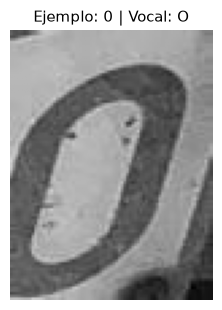

In [14]:
def ver_vocal(ejemplo, X_data=X, y_data=y, ancho=ANCHO, alto=ALTO):
    """Reconstruye y muestra la imagen de la vocal desde su vector plano de características."""
    if hasattr(X_data, "iloc"):
        vector = X_data.iloc[ejemplo].values
        etiqueta = y_data.iloc[ejemplo]
    else:
        vector = X_data[ejemplo]
        etiqueta = y_data[ejemplo]
    
    imagen = vector.reshape([alto, ancho])
    plt.figure(figsize=(2.6, 3.2))
    plt.imshow(imagen, cmap="gray", vmin=0.0, vmax=1.0)
    plt.title(f"Ejemplo: {ejemplo} | Vocal: {etiqueta}", fontsize=11)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

# Visualizamos el primer ejemplo reconstruido directamente desde la matriz X
ver_vocal(0)


### 11.7 Partición estructurada sin fuga de información (*Data Leakage*)

En el notebook de referencia, la profesora establece una regla metodológica cardinal:
> *"Cualquier transformación de los datos, incluyendo PCA [o escalado], se debe ajustar únicamente en el conjunto de entrenamiento y luego aplicarse a los conjuntos de validación y prueba. Ajustar con todos los datos resultaría en lo que se llama data leakage."*

Adicionalmente, el dataset fue ampliado mediante aumento de datos (*data augmentation*), siguiendo la convención de nombres `aug<id>_<sufijo>`, donde un mismo trazo base (`aug<id>`) genera múltiples variantes.

Para evitar que variantes del mismo trazo se repartan entre entrenamiento y prueba (lo que causaría un sesgo optimista artificial), se implementa una partición agrupada y estratificada (`StratifiedGroupKFold`):
- **Entrenamiento:** $80\%$ de los grupos base ($4.056$ imágenes).
- **Prueba:** $20\%$ de los grupos base ($1.014$ imágenes), reservadas estrictamente para la evaluación final de todos los modelos.


In [15]:
from sklearn.model_selection import StratifiedGroupKFold

# Identificador del grupo base a partir del nombre del archivo (ej. 'aug1001_...')
base_id = [re.match(r"aug(\d+)_", Path(r).name).group(1) for r in df["ruta"]]
grupos = np.array([f"{c}_{b}" for c, b in zip(df["clase"], base_id)])

# Partición agrupada y estratificada (80% entrenamiento, 20% prueba)
particionador = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_indices, test_indices = next(particionador.split(X, y, grupos))

X_train, X_test = X[train_indices], X[test_indices]
y_train, y_test = y[train_indices], y[test_indices]
grupos_train, grupos_test = grupos[train_indices], grupos[test_indices]

# Creación de DataFrames con índices secuenciales para trazabilidad (estilo MNIST de la profesora)
train_index = range(0, len(X_train))
test_index = range(len(X_train), len(X_train) + len(X_test))

df_X_train = pd.DataFrame(data=X_train, index=train_index)
s_y_train = pd.Series(data=y_train, index=train_index, name="vocal")

df_X_test = pd.DataFrame(data=X_test, index=test_index)
s_y_test = pd.Series(data=y_test, index=test_index, name="vocal")

print("Dimensiones de las particiones creadas:")
print("  Entrenamiento: %d ejemplos con %d características" % X_train.shape)
print("  Prueba:        %d ejemplos con %d características" % X_test.shape)
print("  Grupos compartidos entre entrenamiento y prueba:", len(set(grupos_train) & set(grupos_test)))
print("\nDistribución de clases en el conjunto de prueba:")
print(pd.Series(y_test).value_counts().reindex(VOCALES).to_string())


Dimensiones de las particiones creadas:
  Entrenamiento: 4056 ejemplos con 7500 características
  Prueba:        1014 ejemplos con 7500 características
  Grupos compartidos entre entrenamiento y prueba: 0

Distribución de clases en el conjunto de prueba:
A    202
E    202
I    202
O    206
U    202


### 11.8 Análisis de varianza de los píxeles (Redundancia de variables)

Al tratar cada píxel como una variable independiente, se dispone de $7.500$ variables. Siguiendo el análisis del cuaderno de la profesora sobre MNIST, muchas de estas columnas corresponden a bordes o esquinas de la imagen donde no hay trazo manuscrito (el valor de intensidad es casi idéntico en todas las muestras).

El cálculo de la varianza a lo largo del conjunto de entrenamiento permite identificar qué porcentaje de las variables aporta variación real y cuáles tienen varianza nula o casi nula.


Resumen de varianza de las variables (píxeles):
  Número total de variables:             7500
  Variables constantes (varianza cero):  0
  Variables con varianza menor a 0.005:  0 (0.0%)


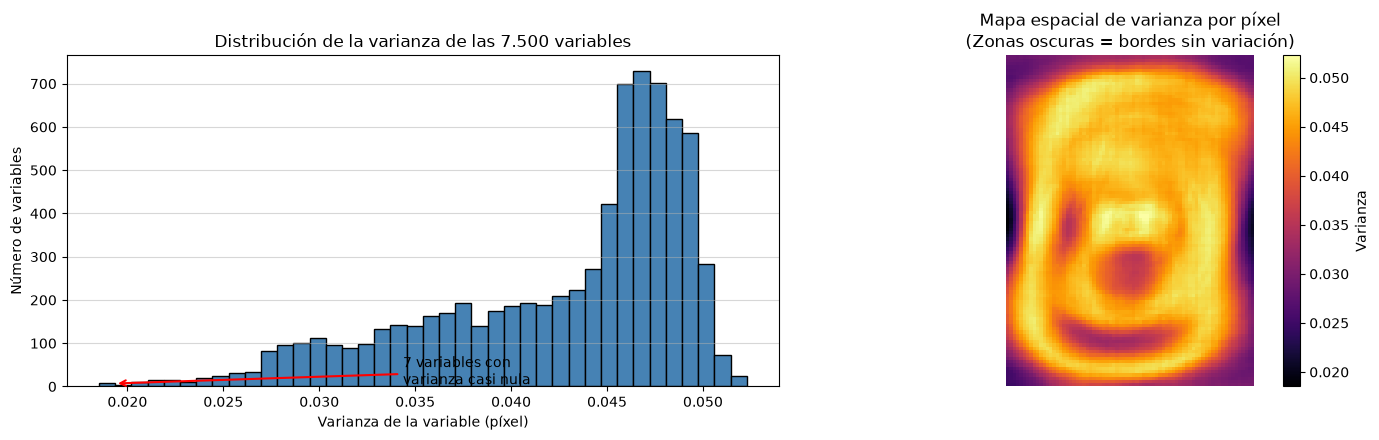

In [16]:
# Varianza de cada píxel a lo largo de los ejemplos de entrenamiento
varianza_pixeles = X_train.var(axis=0)

n_total = X_train.shape[1]
n_constantes = int((varianza_pixeles == 0).sum())
n_casi_constantes = int((varianza_pixeles < 0.005).sum())

print("Resumen de varianza de las variables (píxeles):")
print("  Número total de variables:             %d" % n_total)
print("  Variables constantes (varianza cero):  %d" % n_constantes)
print("  Variables con varianza menor a 0.005:  %d (%.1f%%)" % (n_casi_constantes, (n_casi_constantes / n_total) * 100))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Histograma de varianzas
conteos, bordes, _ = axes[0].hist(varianza_pixeles, bins=40, color="steelblue", edgecolor="black")
axes[0].set_xlabel("Varianza de la variable (píxel)")
axes[0].set_ylabel("Número de variables")
axes[0].set_title("Distribución de la varianza de las 7.500 variables")
axes[0].annotate(f"{conteos[0]:.0f} variables con\nvarianza casi nula",
                 xy=(bordes[1], conteos[0]),
                 xytext=(bordes[1] + 0.015, conteos[0] * 0.75),
                 arrowprops=dict(arrowstyle="->", color="red", lw=1.5))
axes[0].grid(True, axis="y", alpha=0.5)

# Mapa espacial 2D de la varianza por píxel
mapa_varianza = varianza_pixeles.reshape((ALTO, ANCHO))
im_var = axes[1].imshow(mapa_varianza, cmap="inferno")
axes[1].set_title("Mapa espacial de varianza por píxel\n(Zonas oscuras = bordes sin variación)")
axes[1].axis("off")
fig.colorbar(im_var, ax=axes[1], fraction=0.046, pad=0.04, label="Varianza")

plt.tight_layout()
plt.show()


### 11.9 Reducción de dimensionalidad con PCA (Análisis de Componentes Principales)

El Análisis de Componentes Principales (PCA) proyecta las $7.500$ variables originales sobre un nuevo conjunto de ejes ortogonales (componentes principales), ordenados de mayor a menor varianza explicada.

**Fundamentos metodológicos (aplicados según el cuaderno de la profesora):**
1. **Centrado:** `PCA` centra las variables automáticamente restando su media.
2. **Escalado:** Todas las variables comparten la misma escala continua $[0.0, 1.0]$.
3. **Prevención de fuga:** El modelo PCA se ajusta (`fit`) **únicamente sobre el conjunto de entrenamiento** (`X_train`). El conjunto de prueba (`X_test`) únicamente se proyecta (`transform`) usando el modelo ya ajustado.

Se evalúa la varianza explicada acumulada y se determina el número de componentes necesario para retener el **95 % de la varianza**.

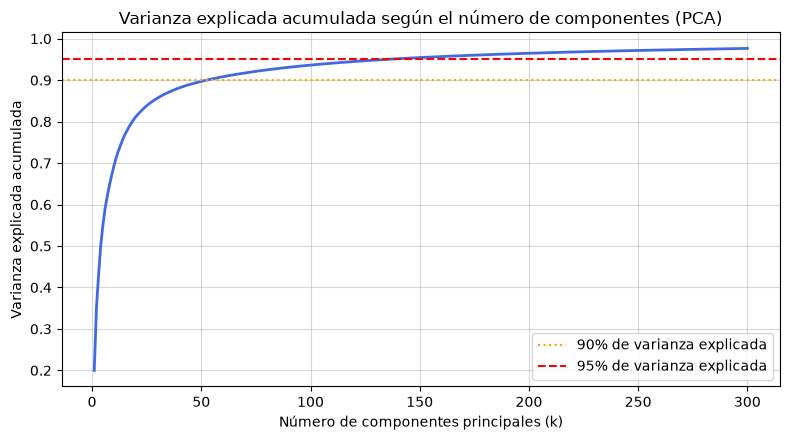

Componentes necesarias para el 90% de la varianza: k = 53
Componentes necesarias para el 95% de la varianza: k = 135 (de 7.500 iniciales, reducción del 98.2%)



Dimensiones de los datos reducidos con PCA (95% de varianza):
  X_train_pca: (4056, 135)
  X_test_pca:  (1014, 135)


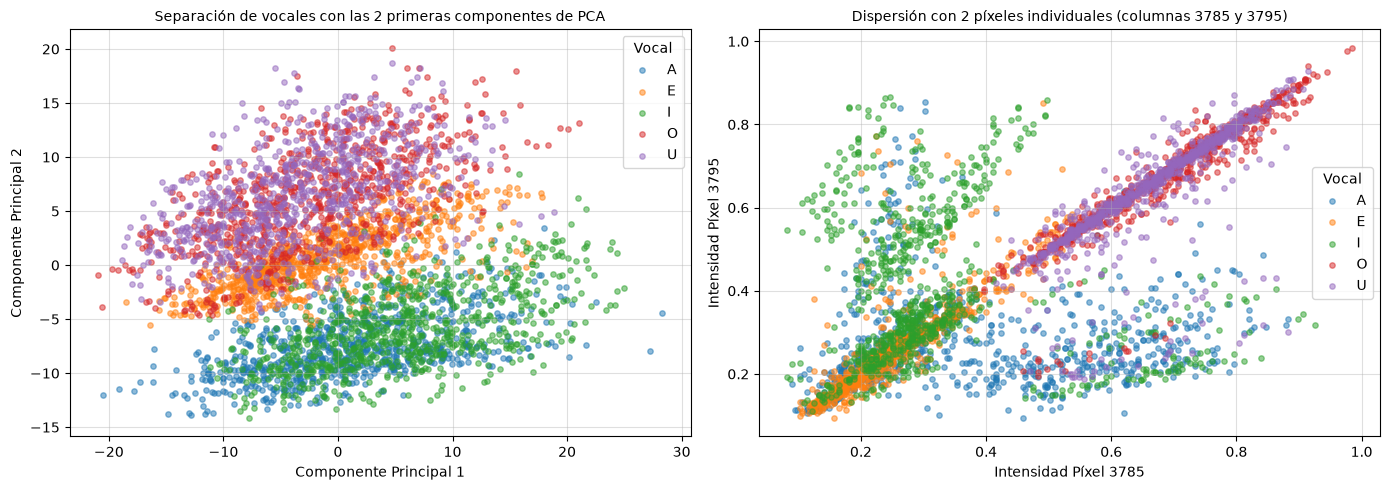

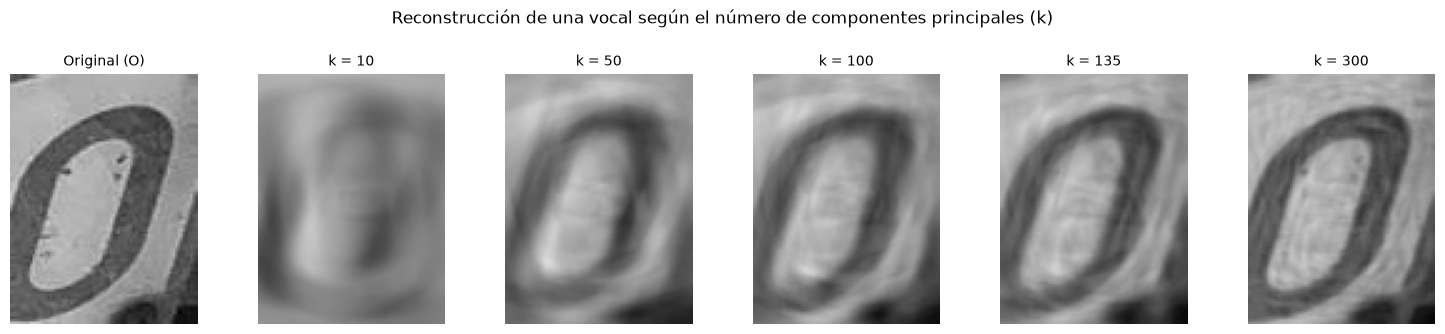

In [17]:
from sklearn.decomposition import PCA

# 1) Ajuste exploratorio de PCA en entrenamiento (300 componentes principales)
pca_exploratorio = PCA(n_components=300, svd_solver="randomized", random_state=42)
pca_exploratorio.fit(X_train)

varianza_acumulada = np.cumsum(pca_exploratorio.explained_variance_ratio_)

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, lw=2, color="royalblue")
plt.axhline(y=0.90, color="orange", linestyle=":", label="90% de varianza explicada")
plt.axhline(y=0.95, color="red", linestyle="--", label="95% de varianza explicada")
plt.xlabel("Número de componentes principales (k)")
plt.ylabel("Varianza explicada acumulada")
plt.title("Varianza explicada acumulada según el número de componentes (PCA)")
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

# Identificación de componentes necesarias para umbrales clave
k_90 = int(np.searchsorted(varianza_acumulada, 0.90) + 1)
k_95 = int(np.searchsorted(varianza_acumulada, 0.95) + 1)
print(f"Componentes necesarias para el 90% de la varianza: k = {k_90}")
print(f"Componentes necesarias para el 95% de la varianza: k = {k_95} (de 7.500 iniciales, reducción del {(1 - k_95/7500)*100:.1f}%)")

# 2) Ajuste del PCA definitivo para el 95% de varianza
pca_95 = PCA(n_components=k_95, svd_solver="randomized", random_state=42)
X_train_pca = pca_95.fit_transform(X_train)
X_test_pca = pca_95.transform(X_test)  # Sin fit: estrictamente transform para evitar data leakage

print("\nDimensiones de los datos reducidos con PCA (95% de varianza):")
print("  X_train_pca:", X_train_pca.shape)
print("  X_test_pca: ", X_test_pca.shape)

# 3) Visualización en 2D: Primeras 2 componentes de PCA vs. 2 píxeles individuales
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for vocal in VOCALES:
    mask = (y_train == vocal)
    axes[0].scatter(X_train_pca[mask, 0], X_train_pca[mask, 1], label=vocal, alpha=0.5, s=15)
axes[0].set_title("Separación de vocales con las 2 primeras componentes de PCA", fontsize=10)
axes[0].set_xlabel("Componente Principal 1")
axes[0].set_ylabel("Componente Principal 2")
axes[0].legend(title="Vocal")
axes[0].grid(True, alpha=0.4)

p1, p2 = 3785, 3795
for vocal in VOCALES:
    mask = (y_train == vocal)
    axes[1].scatter(X_train[mask, p1], X_train[mask, p2], label=vocal, alpha=0.5, s=15)
axes[1].set_title(f"Dispersión con 2 píxeles individuales (columnas {p1} y {p2})", fontsize=10)
axes[1].set_xlabel(f"Intensidad Píxel {p1}")
axes[1].set_ylabel(f"Intensidad Píxel {p2}")
axes[1].legend(title="Vocal")
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

# 4) Reconstrucción visual de una vocal según distintos números de componentes k
ejemplo_idx = 0
valores_k = [10, 50, 100, k_95, 300]
z_ejemplo = pca_exploratorio.transform(X_train[[ejemplo_idx]])[0]

fig, ejes = plt.subplots(1, len(valores_k) + 1, figsize=(15, 3.2))
ejes[0].imshow(X_train[ejemplo_idx].reshape(ALTO, ANCHO), cmap="gray", vmin=0.0, vmax=1.0)
ejes[0].set_title(f"Original ({y_train[ejemplo_idx]})", fontsize=10)
ejes[0].axis("off")

for eje, k in zip(ejes[1:], valores_k):
    x_reconstruido = pca_exploratorio.mean_ + z_ejemplo[:k] @ pca_exploratorio.components_[:k, :]
    eje.imshow(x_reconstruido.reshape(ALTO, ANCHO), cmap="gray", vmin=0.0, vmax=1.0)
    eje.set_title(f"k = {k}", fontsize=10)
    eje.axis("off")

plt.suptitle("Reconstrucción de una vocal según el número de componentes principales (k)", y=1.03)
plt.tight_layout()
plt.show()


### 11.10 Estandarización y contrato de datos para el equipo

Con esta fase completada, los datos quedan estructurados de forma homogénea para que cada integrante del equipo implemente y ajuste su método respectivo con `GridSearchCV`:

| Integrante | Método Asignado | Datos de Entrada recomendados | Validación Cruzada en `GridSearchCV` |
| :--- | :--- | :--- | :--- |
| **Carlos Pinto** | Regresión Multivariada (Logística Multinomial) | `X_train_pca`, `y_train` (o `X_train`) | `StratifiedGroupKFold(n_splits=5)` con `grupos_train` |
| **Jorge García** | Random Forest | `X_train_pca` o `X_train`, `y_train` | `StratifiedGroupKFold(n_splits=5)` con `grupos_train` |
| **Santiago Gonzales** | Árboles de Decisión | `X_train_pca` o `X_train`, `y_train` | `StratifiedGroupKFold(n_splits=5)` con `grupos_train` |
| **León Cantillo** | Redes Neuronales (MLP y DNN) | `X_train`, `y_train` (o `X_train_pca`) | `StratifiedGroupKFold(n_splits=5)` con `grupos_train` |

**Variables y objetos disponibles en memoria para todos los modelos:**
- `X_train`, `y_train`: Datos de entrenamiento normalizados $[0.0, 1.0]$ en el espacio original de $7.500$ píxeles ($4.056$ ejemplos).
- `X_test`, `y_test`: Datos de prueba reservados para evaluación final ($1.014$ ejemplos).
- `X_train_pca`, `X_test_pca`: Datos transformados con PCA conservando el $95\%$ de varianza ($k = 135$ variables).
- `grupos_train`: Vector de grupos de trazo base para configurar la validación cruzada agrupada sin sesgo por aumento.
- `ver_vocal(idx)`: Función para inspección visual de cualquier ejemplo o predicción.


In [18]:
# Verificación final de los objetos compartidos para todos los métodos
print("=== CONTRATO DE DATOS PREPARADOS PARA EL EQUIPO ===")
print(f"1. Espacio Original:   X_train = {X_train.shape} | X_test = {X_test.shape} (tipo: {X_train.dtype})")
print(f"2. Espacio PCA (95%):  X_train_pca = {X_train_pca.shape} | X_test_pca = {X_test_pca.shape} (tipo: {X_train_pca.dtype})")
print(f"3. Etiquetas:          y_train = {y_train.shape} | y_test = {y_test.shape} (Clases: {np.unique(y_train)})")
print(f"4. Grupos (sin fuga):  grupos_train = {grupos_train.shape} | grupos únicos = {len(np.unique(grupos_train))}")
print("\nDatos listos para: Pinto (Regresión), García (Random Forest), Gonzales (Árboles) y Cantillo (Redes Neuronales).")


=== CONTRATO DE DATOS PREPARADOS PARA EL EQUIPO ===
1. Espacio Original:   X_train = (4056, 7500) | X_test = (1014, 7500) (tipo: float32)
2. Espacio PCA (95%):  X_train_pca = (4056, 135) | X_test_pca = (1014, 135) (tipo: float32)
3. Etiquetas:          y_train = (4056,) | y_test = (1014,) (Clases: ['A' 'E' 'I' 'O' 'U'])
4. Grupos (sin fuga):  grupos_train = (4056,) | grupos únicos = 3864

Datos listos para: Pinto (Regresión), García (Random Forest), Gonzales (Árboles) y Cantillo (Redes Neuronales).
